# Method of lines, diffusion and grid refinement

**Source:** CompSci §§5.1–5.3.3, pp. 37–45 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

Use $N$ periodic nodes $j\Delta x$ with $\Delta x=L/N$ and no duplicate endpoint. Taylor expansions give the centred first derivative and three-point Laplacian. Discretising only space gives $c'=Ac$, where $A=-uD_0+DD_2$. Forward Euler gives $M=I+hA$, backward Euler solves $(I-hA)c^{n+1}=c^n$, and Crank–Nicolson solves $(I-hA/2)c^{n+1}=(I+hA/2)c^n$. The centred explicit residual for smooth solutions is $O(h+\Delta x^2)$. Refinement must stay in a stable regime.

For periodic constant coefficients, Fourier modes diagonalise the update; $|G|\le1$ for all modes is equivalent to a nonexpansive discrete 2-norm. Directly, a compatible matrix norm $\|M\|\le1$ is sufficient. Diffusion gives $G_{\rm FE}=1-4r\sin^2(\theta/2)$ and $G_{\rm BE}=1/[1+4r\sin^2(\theta/2)]$ with $r=Dh/\Delta x^2$. Thus $r\le1/2$ suffices for explicit stability and backward Euler is stable for every $r\ge0$.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


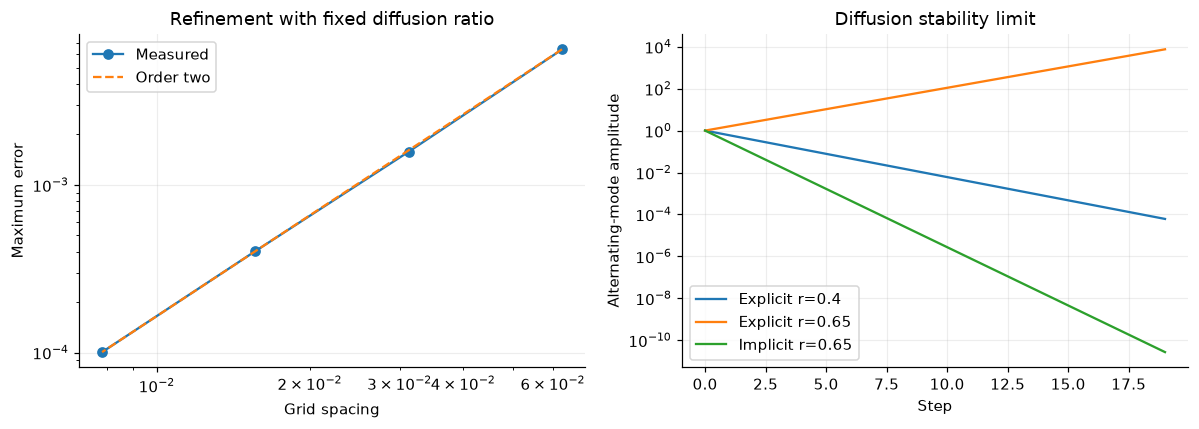

Observed coupled refinement order: 2.0015556137610546


In [2]:
def explicit(v,r,n):
    for _ in range(n): v=v+r*(np.roll(v,-1)-2*v+np.roll(v,1))
    return v

ns=np.array([16,32,64,128]); errors=[]
for n in ns:
    x=np.arange(n)/n; end=.02
    k=int(np.ceil(end*n*n/.4)); r=end*n*n/k
    start=np.sin(2*np.pi*x)
    errors.append(np.max(abs(explicit(start,r,k)-np.exp(-4*np.pi**2*end)*start)))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].loglog(1/ns,errors,"o-",label="Measured")
ax[0].loglog(1/ns,errors[-1]*(ns[-1]/ns)**2,"--",label="Order two")
ax[0].set(xlabel="Grid spacing",ylabel="Maximum error",title="Refinement with fixed diffusion ratio"); ax[0].legend()
steps=np.arange(20)
for r in [.4,.65]:
    ax[1].semilogy(steps,abs(1-4*r)**steps,label=f"Explicit r={r}")
ax[1].semilogy(steps,(1+4*.65)**(-steps),label="Implicit r=0.65")
ax[1].set(xlabel="Step",ylabel="Alternating-mode amplitude",title="Diffusion stability limit"); ax[1].legend()
show(fig,"05-diffusion-grid")
rate=np.log2(errors[-2]/errors[-1]); assert 1.85<rate<2.15
assert np.isclose(np.max(abs(explicit((-1.)**np.arange(16),.65,4))),1.6**4)
print("Observed coupled refinement order:",rate)

## Worked exercise

**What happens to an explicit timestep when the grid spacing is halved?** The diffusion limit requires it to fall by a factor of four. Implicit methods remove this bound for the stated linear model, but involve a solve and still incur time error.

## Additional experiment

Direct matrix norms and growth of a small high-frequency perturbation.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

In [ ]:
N=64;dx=1/N;D=.1;x=np.arange(N)*dx
L=(np.roll(np.eye(N),1,axis=1)-2*np.eye(N)+np.roll(np.eye(N),-1,axis=1))/dx**2
fig,ax=plt.subplots(1,2,figsize=(10,4))
for r in [.4,.6]:
 dt=r*dx*dx/D;M=np.eye(N)+dt*D*L
 c=np.sin(2*np.pi*x)+1e-5*(-1.)**np.arange(N);history=[]
 for _ in range(80):history.append(np.linalg.norm(c));c=M@c
 ax[0].semilogy(np.arange(80)*dt,history,label=f"r={r}")
 print(r,"matrix norm:",np.linalg.norm(M,2))
theta=np.linspace(0,np.pi,200)
for r in [.4,.6]:ax[1].plot(theta,abs(1-4*r*np.sin(theta/2)**2),label=f"r={r}")
ax[0].set(xlabel="time",ylabel="solution norm");ax[1].set(xlabel="grid phase",ylabel="|G|");ax[0].legend();ax[1].legend();plt.tight_layout();plt.show()
assert np.linalg.norm(np.eye(N)+.4*dx*dx*L,2)<1+1e-12

## Further practice

Run implicit Euler at r=5 and compare to the exact decaying sine at the same final time. Measure accuracy separately from stability.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.